# Natural Policy Gradient (NPG)

## What I'm building
I want to implement **Natural Policy Gradient** — an improvement over vanilla policy gradient.

### The core idea I'm testing
Vanilla PG:  θ ← θ + α ∇J(θ)          (Euclidean step in parameter space)
Natural PG:  θ ← θ + α F⁻¹ ∇J(θ)      (step measured in *distribution* space)

where `F` is the **Fisher Information Matrix (FIM)**:
F = E[ ∇log π(a|s) · ∇log π(a|s)ᵀ ]

### Why the FIM matters
The FIM is the local metric of KL divergence between policies:
KL(π_θ || π_{θ+δ}) ≈ ½ δᵀ F δ

So `F⁻¹∇J` gives the **steepest ascent direction in the space of policies**
(not in raw parameter coordinates). This should give me:
- Scale-invariant updates (no per-parameter LR tuning)
- More stable and faster learning than vanilla PG

## 1. Imports
I'll use Gymnasium's `CartPole-v1` as a simple testbed.
CartPole's observation is continuous, so I'll **discretize** it into bins
so a simple tabular softmax policy can handle it (keeps the math transparent).

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

np.random.seed(0)

## 2. The Softmax Policy

I'll use a linear-in-parameters policy over discrete states:

π(a|s) = softmax(θ[s])ₐ

Each state `s` has its own parameter vector θ[s] of size `n_actions`.

### Score function (needed for both PG and FIM)
∇_θ log π(a|s) is a matrix with shape (n_states, n_actions).
For one-hot state `s`, only row `s` is non-zero:

∇_θ log π(a|s) [s, :] = -π(·|s)
∇_θ log π(a|s) [s, a] += 1

This "one-hot row" structure makes the Fisher computation easy.

In [2]:
class SoftmaxPolicy:
    def __init__(self, n_states, n_actions, lr=0.01):
        self.theta = np.zeros((n_states, n_actions))
        self.lr = lr
        self.n_states, self.n_actions = n_states, n_actions

    def probs(self, s):
        z = self.theta[s] - self.theta[s].max()
        p = np.exp(z)
        return p / p.sum()

    def sample(self, s):
        return np.random.choice(self.n_actions, p=self.probs(s))

    def score(self, s, a):
        """∇_θ log π(a|s) as a full matrix (only row s non-zero)."""
        grad = np.zeros_like(self.theta)
        p = self.probs(s)
        grad[s] = -p
        grad[s, a] += 1.0
        return grad

## 3. Fisher Information Matrix (FIM)

For a policy, the FIM is:

F = (1/N) Σ ∇log π(aᵢ|sᵢ) ∇log π(aᵢ|sᵢ)ᵀ

It's a (n_states·n_actions) × (n_states·n_actions) matrix —
the **outer product of the score functions** averaged over sampled (s,a).

Because each score is one-hot in the state dimension, F is block-diagonal —
but for a small problem I can just build the full matrix explicitly.

> **Note:** computing the full FIM is O((n_states·n_actions)²) in memory —
> fine for tabular CartPole but not for neural networks. In real code
> I'd solve `F x = g` with conjugate gradient (this is what TRPO does).

In [3]:
def fisher(policy, states, actions):
    n_params = policy.n_states * policy.n_actions
    F = np.zeros((n_params, n_params))
    for s, a in zip(states, actions):
        g = policy.score(s, a).ravel()      # column vector of length n_params
        F += np.outer(g, g)                 # outer product g · gᵀ
    return F / len(states)


def natural_update(policy, states, actions, advantages):
    """Block-diagonal natural gradient: solve F_s x_s = g_s per visited state."""
    n_actions = policy.n_actions

    # 1) vanilla gradient ∇J
    grad = np.zeros_like(policy.theta)
    for s, a, A in zip(states, actions, advantages):
        grad += A * policy.score(s, a)
    grad /= len(states)

    # 2) group the observed (a, A) by state so we can build per-state FIM blocks
    from collections import defaultdict
    by_state = defaultdict(list)   # s -> list of (a, A)
    for s, a, A in zip(states, actions, advantages):
        by_state[s].append((a, A))

    # 3) for each visited state, solve the tiny F_s x_s = g_s system
    nat_grad = np.zeros_like(policy.theta)
    for s, pairs in by_state.items():
        # score vectors g_s(a) = e_a - π(·|s)   (shape: n_actions)
        p = policy.probs(s)
        F_s = np.zeros((n_actions, n_actions))
        g_s = np.zeros(n_actions)                # vanilla grad for this state
        for a, A in pairs:
            score_a = -p.copy()
            score_a[a] += 1.0                    # ∇log π(a|s) restricted to row s
            F_s += np.outer(score_a, score_a)
            g_s += A * score_a
        F_s /= len(pairs)
        g_s /= len(pairs)
        F_s += 1e-3 * np.eye(n_actions)          # damping
        nat_grad[s] = np.linalg.solve(F_s, g_s)

    # 4) update only the visited states
    policy.theta += policy.lr * nat_grad

In [4]:
SoftmaxPolicy.fisher = lambda self, s, a: fisher(self, s, a)
SoftmaxPolicy.natural_update = natural_update

## 4. Rollout & Discounted Returns

- `rollout(...)` runs the current policy for one episode, collecting
  `(state, action, reward)` tuples.
- `compute_returns(...)` computes the discounted return `Gₜ` for each step.
- I use `Gₜ` (normalized) as a **simple advantage estimate**
  (this is REINFORCE-style; NPG is agnostic to how you estimate advantage).

In [5]:
def rollout(env, policy, discrete_fn, max_steps=500):
    states, actions, rewards = [], [], []
    s, _ = env.reset()
    for _ in range(max_steps):
        ds = discrete_fn(s)
        a = policy.sample(ds)
        s2, r, done, trunc, _ = env.step(a)
        states.append(ds); actions.append(a); rewards.append(r)
        s = s2
        if done or trunc:
            break
    return states, actions, rewards


def compute_returns(rewards, gamma=0.99):
    G, out = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G
        out.append(G)
    return np.array(out[::-1])


def normalize(x):
    return (x - x.mean()) / (x.std() + 1e-8)

## 5. Discretizing CartPole

CartPole state = (cart_position, cart_velocity, pole_angle, pole_velocity) — all continuous.
I'll bin each dimension into `n_bins` buckets → a small tabular state space.
This keeps the Fisher matrix small enough to build and invert directly,
so I can actually *see* the NPG update in action without needing a neural network.|

In [6]:
N_BINS = 8

def make_discrete_fn(n_bins=N_BINS):
    # (low, high) ranges for each of the 4 CartPole dims
    bounds = [(-4.8, 4.8), (-4.0, 4.0), (-0.5, 0.5), (-6.0, 6.0)]
    def discrete(s):
        idx = 0
        for v, (lo, hi) in zip(s, bounds):
            b = int((v - lo) / (hi - lo) * n_bins)
            b = min(max(b, 0), n_bins - 1)
            idx = idx * n_bins + b
        return idx
    return discrete

## 6. Training Loop

Each episode I'll:
1. Run a rollout → collect (s, a, r)
2. Compute discounted returns → normalize → advantage
3. Update:
   - `"vanilla"` → θ ← θ + α ∇J
   - `"npg"`     → θ ← θ + α F⁻¹ ∇J
4. Log episode return

I'm watching to see whether NPG **climbs faster** and is **less noisy**
than vanilla PG on the same learning rate, because the FIM rescales
each gradient direction appropriately.|

In [7]:
def train(method="npg", n_episodes=400, lr=0.01, seed=0):
    np.random.seed(seed)
    env = gym.make("CartPole-v1")
    discrete_fn = make_discrete_fn()

    n_states = N_BINS ** 4
    n_actions = env.action_space.n
    policy = SoftmaxPolicy(n_states, n_actions, lr=lr)

    returns_log = []

    for ep in range(n_episodes):
        states, actions, rewards = rollout(env, policy, discrete_fn)
        G = compute_returns(rewards)
        adv = normalize(G)

        if method == "vanilla":
            grad = np.zeros_like(policy.theta)
            for s, a, A in zip(states, actions, adv):
                grad += A * policy.score(s, a)
            policy.theta += policy.lr * grad / len(states)
        else:
            natural_update(policy, states, actions, adv)

        returns_log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"[{method}] ep {ep+1:4d} | avg(last 50) = {np.mean(returns_log[-50:]):6.1f}")

    return returns_log

## 7. Compare Vanilla PG vs NPG

I'll run both algorithms with the **same learning rate, seed, and episode count**
so the comparison is fair. If the FIM is doing its job, NPG should:

- Reach higher returns sooner
- Have smoother learning curves

Note: for CartPole these curves can be a bit noisy — I can try `n_episodes=1000`
or average over several seeds if I want a cleaner picture.

In [8]:
vanilla_returns = train("vanilla", n_episodes=400, lr=0.01, seed=0)
npg_returns     = train("npg",     n_episodes=400, lr=0.01, seed=0)

[vanilla] ep   50 | avg(last 50) =   21.4
[vanilla] ep  100 | avg(last 50) =   18.9
[vanilla] ep  150 | avg(last 50) =   23.2
[vanilla] ep  200 | avg(last 50) =   24.7
[vanilla] ep  250 | avg(last 50) =   21.9
[vanilla] ep  300 | avg(last 50) =   21.4
[vanilla] ep  350 | avg(last 50) =   21.9
[vanilla] ep  400 | avg(last 50) =   23.2
[npg] ep   50 | avg(last 50) =   21.1
[npg] ep  100 | avg(last 50) =   23.4
[npg] ep  150 | avg(last 50) =   30.3
[npg] ep  200 | avg(last 50) =   39.3
[npg] ep  250 | avg(last 50) =   45.6
[npg] ep  300 | avg(last 50) =   42.6
[npg] ep  350 | avg(last 50) =   53.0
[npg] ep  400 | avg(last 50) =   55.8


## 7. Compare Vanilla PG vs NPG

I'll run both algorithms with the **same learning rate, seed, and episode count**
so the comparison is fair. If the FIM is doing its job, NPG should:

- Reach higher returns sooner
- Have smoother learning curves

Note: for CartPole these curves can be a bit noisy — I can try `n_episodes=1000`
or average over several seeds if I want a cleaner picture.

In [9]:
vanilla_returns = train("vanilla", n_episodes=400, lr=0.01, seed=0)
npg_returns     = train("npg",     n_episodes=400, lr=0.01, seed=0)

[vanilla] ep   50 | avg(last 50) =   21.0
[vanilla] ep  100 | avg(last 50) =   24.0
[vanilla] ep  150 | avg(last 50) =   26.5
[vanilla] ep  200 | avg(last 50) =   22.6
[vanilla] ep  250 | avg(last 50) =   22.9
[vanilla] ep  300 | avg(last 50) =   24.1
[vanilla] ep  350 | avg(last 50) =   22.9
[vanilla] ep  400 | avg(last 50) =   24.9
[npg] ep   50 | avg(last 50) =   24.9
[npg] ep  100 | avg(last 50) =   23.6
[npg] ep  150 | avg(last 50) =   32.4
[npg] ep  200 | avg(last 50) =   33.8
[npg] ep  250 | avg(last 50) =   34.9
[npg] ep  300 | avg(last 50) =   47.2
[npg] ep  350 | avg(last 50) =   50.2
[npg] ep  400 | avg(last 50) =   70.5


## 8. Plot the Learning Curves

I'll smooth with a moving average to make the trend easier to see.

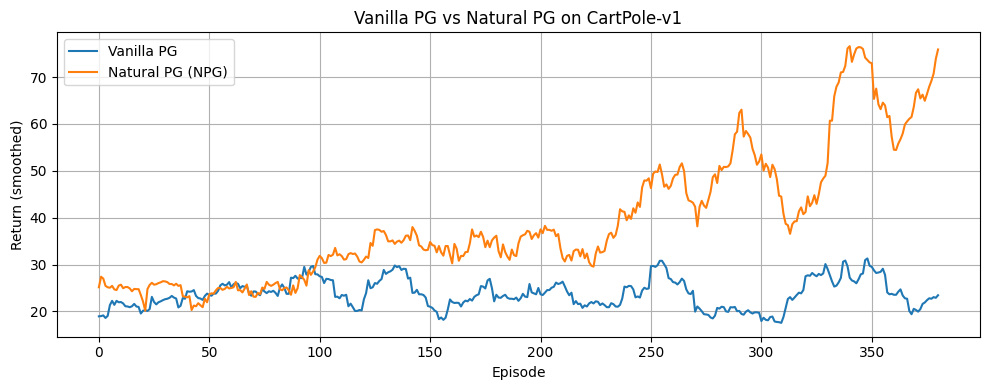

In [10]:
def smooth(x, k=20):
    return np.convolve(x, np.ones(k) / k, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(smooth(vanilla_returns), label="Vanilla PG")
plt.plot(smooth(npg_returns),     label="Natural PG (NPG)")
plt.xlabel("Episode")
plt.ylabel("Return (smoothed)")
plt.title("Vanilla PG vs Natural PG on CartPole-v1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 9. Takeaways

### The NPG update
θ ← θ + α · **F⁻¹ ∇J**

- `∇J` — vanilla policy gradient (steepest ascent in raw parameter space)
- `F` — Fisher Information Matrix of the policy
- `F⁻¹∇J` — steepest ascent in **distribution space** (KL metric)

### Why it beats vanilla PG
1. **Scale-invariant** — behavior doesn't depend on units of θ
2. **Adaptive step size per direction** — the FIM rescales each component
3. **More stable** — damps directions the policy is already confident in

### Practical tips I picked up
- Always **damp** F with `+ εI` (otherwise it's singular).
- Use `np.linalg.solve(F, g)` — never `np.linalg.inv(F) @ g`.
- For big networks: replace the explicit inverse with **conjugate gradient** →
  this is essentially **TRPO** (adds a KL trust region) and **PPO** (adds clipping).

### Where it fits in the family tree
                                 Vanilla PG
└── Natural PG ← this notebook
└── TRPO (CG + KL constraint)
└── PPO (clipping, ~first-order natural step)